## Recap: Centering, Covariance, PCA and Whitening

**Objective:** refresh the linear algebra and statistics we need for Slow Feature Analysis (Sheet 1) and for encoding data (Sheet 2)

**Data:** a correlated 2D toy dataset (so we can see everything), later 8x8 images of handwritten digits

**Notation:**
 * We have $N$ data points $\vec x_1, \dots, \vec x_N \in \mathbb{R}^n$, so every data point has $n$ variables
 * We stack them into a data matrix $X \in \mathbb{R}^{N \times n}$: **one row per data point, one column per variable**
 * $x_i^{(k)}$ is the value of variable $k$ in data point $i$
 * Example: for images, every image is a data point and every pixel is a variable

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

np.random.seed(0)
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 14

def scatter(ax, data, title, lim=None, **kw):
    ax.scatter(*data.T, s=12, alpha=0.6, **kw)
    ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
    if lim is not None:
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect('equal'); ax.set_title(title)
    ax.set_xlabel('variable 1'); ax.set_ylabel('variable 2')

## Generate some data

In [50]:
N = 300
true_mean = np.array([4.0, 2.0])
true_cov = np.array([[3.0, 1.6],
                     [1.6, 1.2]])
X = np.random.multivariate_normal(true_mean, true_cov, size=N)
X.shape   # (N, n): one row per data point, one column per variable

(300, 2)

## Mean

The center of mass of the data, one value per variable:
$$\vec m = \frac{1}{N}\sum_{i=1}^N \vec x_i \qquad\text{i.e.}\qquad m^{(k)} = \frac{1}{N}\sum_{i=1}^N x_i^{(k)}$$

In [51]:
m = X.mean(axis=0)   # average over the data points (axis 0) for every variable
m

array([4.15269951, 2.07475381])

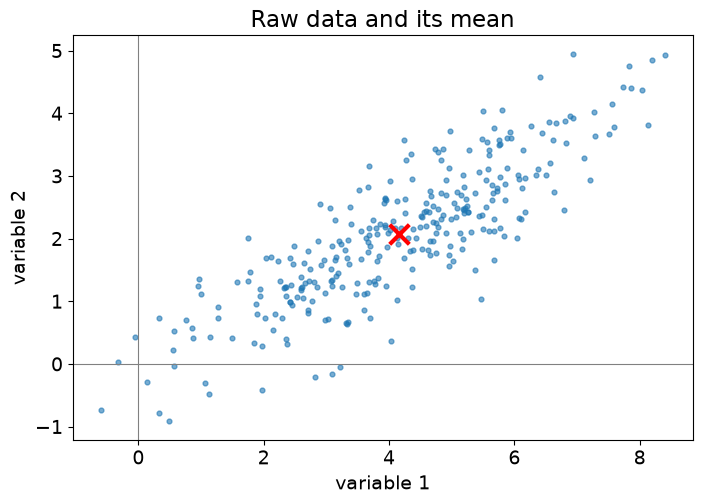

In [27]:
fig, ax = plt.subplots()
scatter(ax, X, 'Raw data and its mean')
ax.scatter(*m, color='red', marker='x', s=200, lw=3)

## Data centering

Subtract the mean from every data point:
$$\vec x_i \mapsto \vec x_i - \vec m$$
This moves the data cloud to the origin.

In [28]:
Xc = X - m   # broadcasting subtracts m from every row
Xc.mean(axis=0).round(10)

array([-0.,  0.])

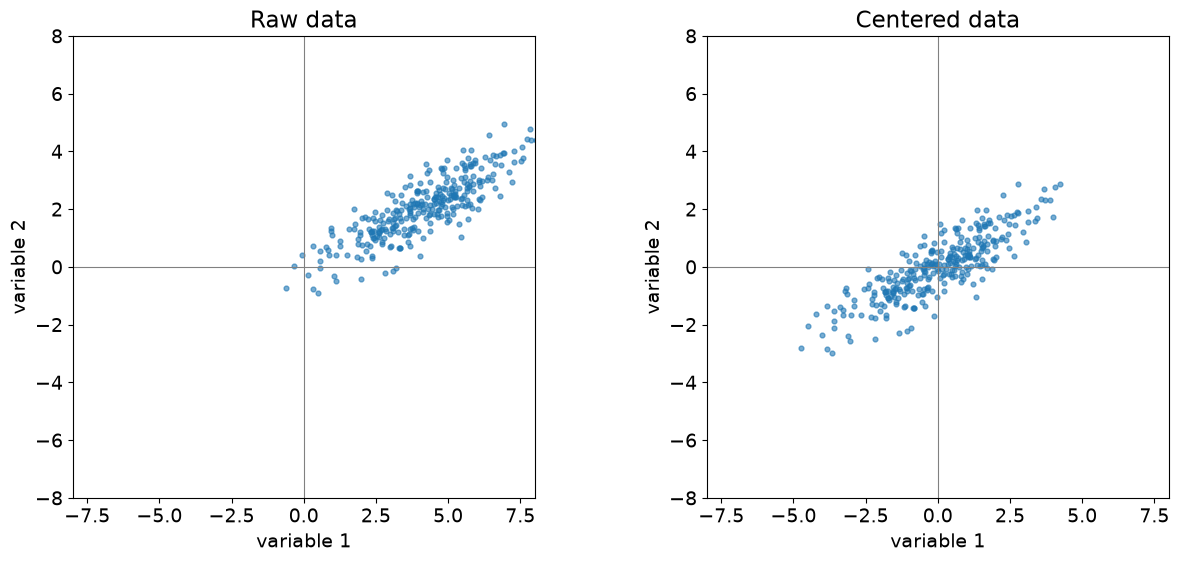

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
scatter(axs[0], X, 'Raw data', lim=8)
scatter(axs[1], Xc, 'Centered data', lim=8)

## Variance

The spread of **one** variable $k$ around its mean:
$$\sigma_k^2 = \frac{1}{N}\sum_{i=1}^N \left(x_i^{(k)} - m^{(k)}\right)^2$$

In [30]:
var = (Xc**2).mean(axis=0)   # one variance per variable
var, X.var(axis=0)

(array([3.06619636, 1.21705423]), array([3.06619636, 1.21705423]))

## Covariance

How **two** variables $k$ and $l$ vary together:
$$C_{kl} = \frac{1}{N}\sum_{i=1}^N \left(x_i^{(k)} - m^{(k)}\right)\left(x_i^{(l)} - m^{(l)}\right)$$
All pairs together give the covariance matrix
$$C = \frac{1}{N}\sum_{i=1}^N (\vec x_i - \vec m)(\vec x_i - \vec m)^t \in \mathbb{R}^{n \times n}$$
The variances are on the diagonal. $C$ is symmetric and positive semidefinite.

In [31]:
C = Xc.T @ Xc / N   # (n, N) @ (N, n) = (n, n)
C

array([[3.06619636, 1.63685579],
       [1.63685579, 1.21705423]])

In [32]:
# numpy gives the same result. bias=True divides by N instead of N-1
np.cov(X, rowvar=False, bias=True)

array([[3.06619636, 1.63685579],
       [1.63685579, 1.21705423]])

In [33]:
# Classic bug: by default np.cov treats every ROW as a variable!
np.cov(X).shape

(300, 300)

What does the sign of $C_{12}$ tell us?

<details>
  <summary>Answer</summary>
  Positive: both variables tend to be large at the same time. Negative: when one is large, the other tends to be small. Zero: no <i>linear</i> relation (there can still be a nonlinear one).
</details>

## Variance along a direction

Project every centered data point onto a unit vector $\vec w$:
$$y_i = \vec w^{\,t}(\vec x_i - \vec m)$$
The variance of these projections is
$$\frac{1}{N}\sum_{i=1}^N y_i^2 = \vec w^{\,t} C\, \vec w$$
Move the slider: in which direction is the variance largest, in which smallest?

In [ ]:
angles = np.linspace(0, 180, 361)
W = np.stack([np.cos(np.deg2rad(angles)), np.sin(np.deg2rad(angles))], axis=1)
var_curve = np.einsum('ij,jk,ik->i', W, C, W)   # w^t C w for every angle

def show_direction(angle=0.0):
    w = np.array([np.cos(np.deg2rad(angle)), np.sin(np.deg2rad(angle))])
    y = Xc @ w             # coordinate of every data point along w
    proj = np.outer(y, w)  # the projected points, drawn in 2D
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    scatter(ax1, Xc, f'Projection onto w, variance = {y.var():.2f}', lim=6)
    ax1.plot(*np.stack([-8 * w, 8 * w]).T, color='black')
    ax1.scatter(*proj.T, s=12, color='C1', zorder=3)
    ax2.plot(angles, var_curve)
    ax2.axvline(angle, color='C1')
    ax2.set_xlabel('angle of w (degrees)'); ax2.set_ylabel('variance along w')
    ax2.set_title('$w^t C w$')
    plt.show()

interact(show_direction, angle=FloatSlider(value=0, min=0, max=180, step=1));

interactive(children=(FloatSlider(value=0.0, description='angle', max=180.0, step=1.0), Output()), _dom_classe…

What is the angle between the direction of largest and the direction of smallest variance?

<details>
  <summary>Answer</summary>
  90 degrees. These two directions are the <b>principal components</b>, and they are exactly the eigenvectors of $C$.
</details>

## Principal components

Since $C$ is symmetric, it has an eigendecomposition with orthonormal eigenvectors:
$$C = V D V^t$$
 * The columns $\vec v_j$ of $V$ are the **principal components**
 * The diagonal entries $\lambda_j$ of $D$ are the **variances along them**
 * Sorted from large to small: the first PC is the direction of largest variance, the second the largest variance direction orthogonal to the first, and so on
 * The eigenvectors with the **smallest** eigenvalues are called *minor components*. SFA needs those!

In [35]:
d, V = np.linalg.eigh(C)      # eigh is for symmetric matrices, returns eigenvalues in ascending order
order = np.argsort(d)[::-1]   # sort from largest to smallest variance
d, V = d[order], V[:, order]

print('eigenvalues (variances along the PCs):', d.round(3))
print('principal components (columns):\n', V.round(3))
print('angle of PC 1:      ', round(np.rad2deg(np.arctan2(V[1, 0], V[0, 0])) % 180, 1))
print('maximum of slider:  ', angles[var_curve.argmax()])
# Note: eigenvectors are only defined up to their sign, -v is just as good as v

eigenvalues (variances along the PCs): [4.022 0.262]
principal components (columns):
 [[-0.864  0.504]
 [-0.504 -0.864]]
angle of PC 1:       30.3
maximum of slider:   30.5


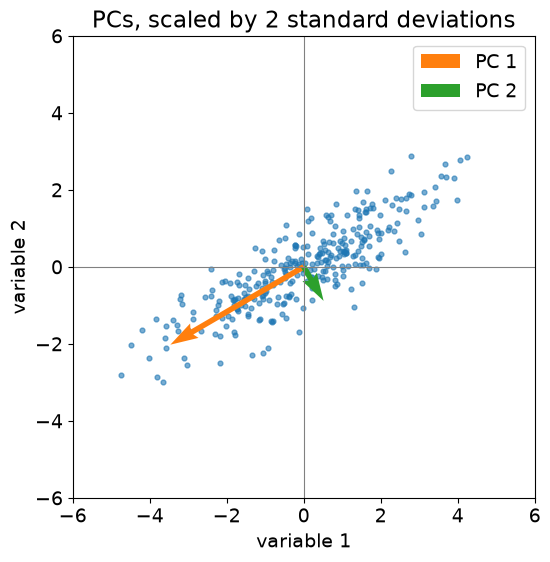

In [37]:
fig, ax = plt.subplots()
scatter(ax, Xc, 'PCs, scaled by 2 standard deviations', lim=6)
for j in range(2):
    ax.quiver(0, 0, *(2 * np.sqrt(d[j]) * V[:, j]), angles='xy', scale_units='xy', scale=1,
              color=f'C{j+1}', width=0.012, label=f'PC {j+1}')
ax.legend()

## Data whitening

Transform the data so that its covariance becomes the identity:
$$\tilde{\vec x}_i = D^{-1/2}\, V^t (\vec x_i - \vec m)$$
Three steps:
1) **center** ($-\vec m$)
2) **rotate** into the PC basis ($V^t$)
3) **scale** every axis to unit variance ($D^{-1/2}$)

Since our data points are rows, $V^t \vec x_i$ for all points becomes `Xc @ V` in code.

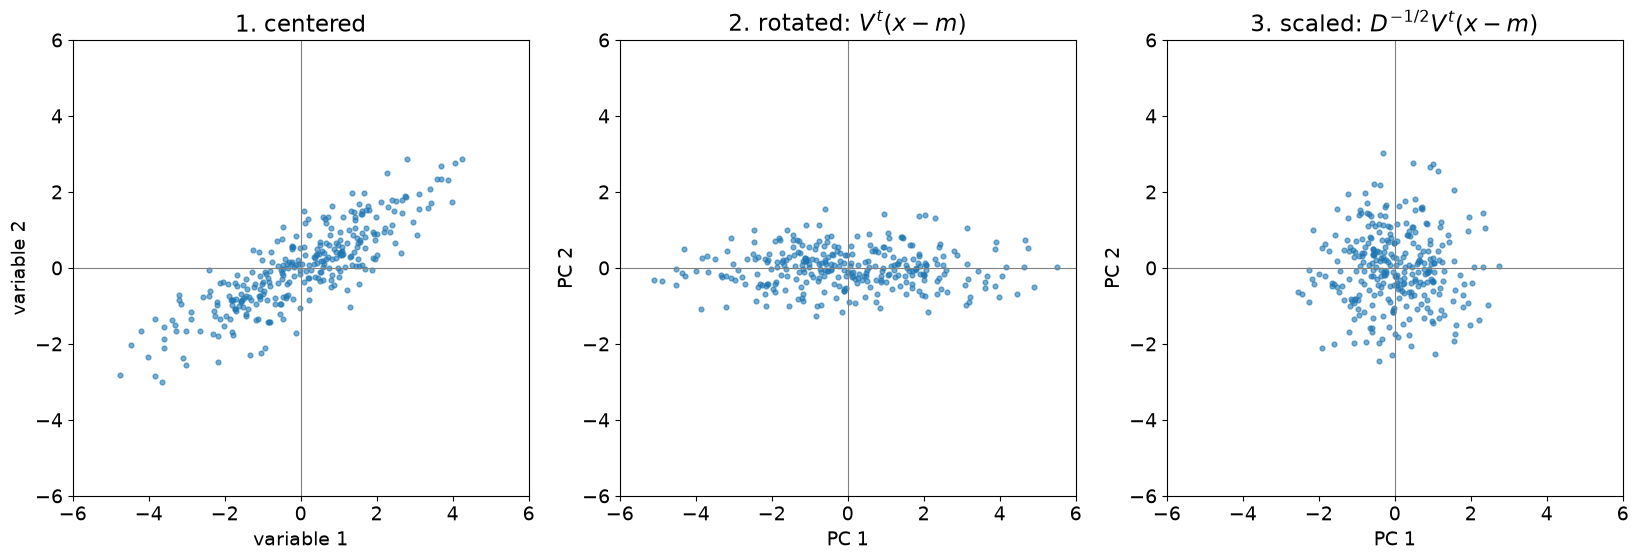

In [38]:
X_rot = Xc @ V                 # step 2: rotate
X_white = X_rot / np.sqrt(d)   # step 3: scale

fig, axs = plt.subplots(1, 3, figsize=(20, 6))
scatter(axs[0], Xc, '1. centered', lim=6)
scatter(axs[1], X_rot, '2. rotated: $V^t(x-m)$', lim=6)
scatter(axs[2], X_white, '3. scaled: $D^{-1/2}V^t(x-m)$', lim=6)
for ax in axs[1:]:
    ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2')

In [39]:
np.cov(X_white, rowvar=False, bias=True).round(3)

array([[ 1., -0.],
       [-0.,  1.]])

After whitening, in which direction is the variance largest?

<details>
  <summary>Answer</summary>
  In none of them: for every unit vector $\vec w$ we get $\vec w^{\,t} I\, \vec w = 1$. The cloud is "round". So any further rotation keeps the data white (see below). This is why SFA whitens first: afterwards it only has to search for the right <b>rotation</b>, which it finds with an eigendecomposition of the covariance of the time differences.
</details>

In [40]:
theta = np.deg2rad(30)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
np.cov(X_white @ R.T, rowvar=False, bias=True).round(3)   # still the identity

array([[ 1., -0.],
       [-0.,  1.]])

## Dimensionality reduction via PCA

Keep only the first $K < n$ principal components $V_K = (\vec v_1, \dots, \vec v_K)$:
$$\vec y_i = V_K^t (\vec x_i - \vec m) \in \mathbb{R}^K \qquad \text{reconstruction:}\quad \hat{\vec x}_i = \vec m + V_K\, \vec y_i$$
This is the best linear projection onto $K$ dimensions: it keeps the most variance and has the smallest squared reconstruction error.
$$\text{variance kept} = \frac{\lambda_1 + \dots + \lambda_K}{\lambda_1 + \dots + \lambda_n}$$
Note: we reduce the number of **variables**, not the number of data points.

In [41]:
K = 1
V_K = V[:, :K]
Y = Xc @ V_K          # (N, K): the reduced data
X_hat = Y @ V_K.T + m # back in the original space

print('shape of reduced data:', Y.shape)
print('variance kept:', (d[:K].sum() / d.sum()).round(3))
print('mean squared reconstruction error:', ((X - X_hat)**2).sum(axis=1).mean().round(3))
print('sum of dropped eigenvalues:       ', d[K:].sum().round(3))

shape of reduced data: (300, 1)
variance kept: 0.939
mean squared reconstruction error: 0.262
sum of dropped eigenvalues:        0.262


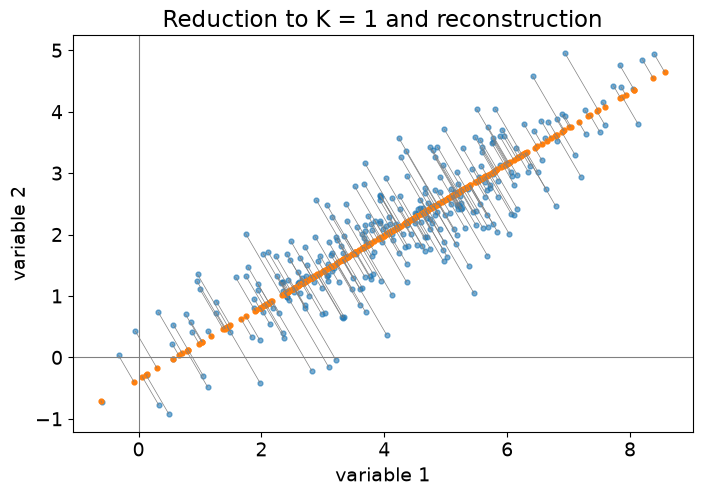

In [42]:
fig, ax = plt.subplots()
for i in range(N):
    ax.plot([X[i, 0], X_hat[i, 0]], [X[i, 1], X_hat[i, 1]], color='grey', lw=0.5)
scatter(ax, X, 'Reduction to K = 1 and reconstruction')
ax.scatter(*X_hat.T, s=12, color='C1')

## Higher dimensions: handwritten digits

Every 8x8 image is one data point with $n = 64$ variables (pixels).

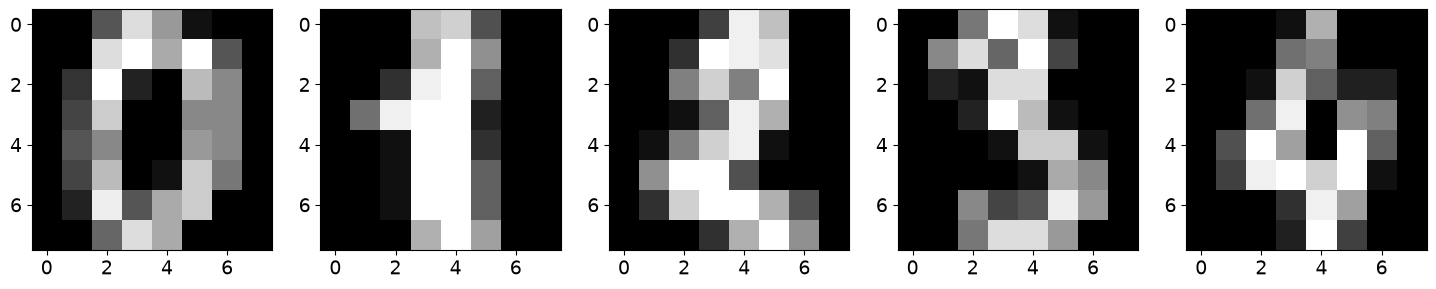

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits().data   # (1797, 64)
m_dig = digits.mean(axis=0)
C_dig = np.cov(digits, rowvar=False, bias=True)
d_dig, V_dig = np.linalg.eigh(C_dig)
order = np.argsort(d_dig)[::-1]
d_dig, V_dig = d_dig[order], V_dig[:, order]

# plot original data
fig, axs = plt.subplots(1, 5, figsize=(18, 3.5))
for i in range(5):
    axs[i].imshow(digits[i].reshape(8, 8), cmap='gray')


How many PCs do we need?

K needed for 95 % of the variance: 29


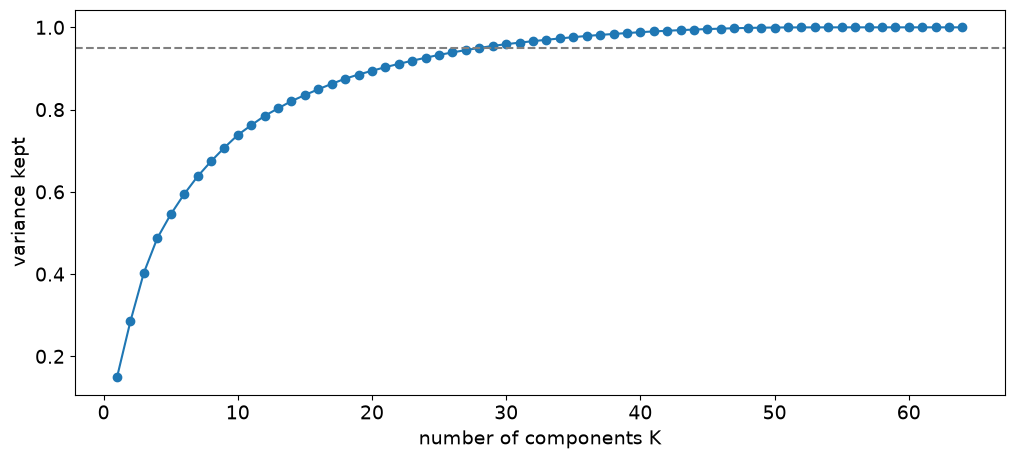

In [48]:
kept = np.cumsum(d_dig) / d_dig.sum()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(np.arange(1, 65), kept, 'o-')
ax.axhline(0.95, color='grey', ls='--')
ax.set_xlabel('number of components K'); ax.set_ylabel('variance kept')
print('K needed for 95 % of the variance:', np.argmax(kept >= 0.95) + 1)

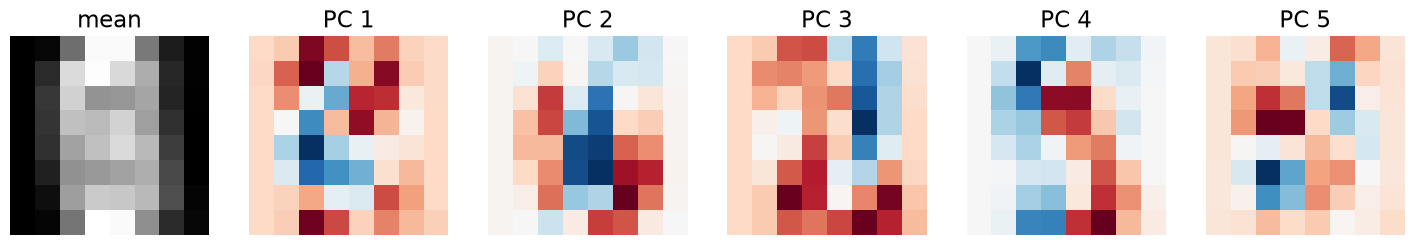

In [ ]:
# The PCs are images themselves ("eigendigits")
fig, axs = plt.subplots(1, 6, figsize=(18, 3.5))
axs[0].imshow(m_dig.reshape(8, 8), cmap='gray'); axs[0].set_title('mean')
for j, ax in enumerate(axs[1:]):
    ax.imshow(V_dig[:, j].reshape(8, 8), cmap='RdBu'); ax.set_title(f'PC {j+1}')
for ax in axs: ax.axis('off')

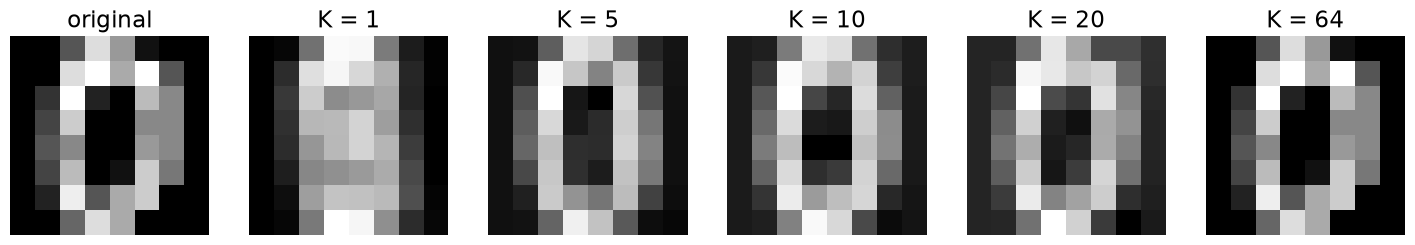

In [45]:
img = digits[0]
Ks = [1, 5, 10, 20, 64]
fig, axs = plt.subplots(1, len(Ks) + 1, figsize=(18, 3.5))
axs[0].imshow(img.reshape(8, 8), cmap='gray'); axs[0].set_title('original')
for ax, K in zip(axs[1:], Ks):
    V_K = V_dig[:, :K]
    rec = (img - m_dig) @ V_K @ V_K.T + m_dig
    ax.imshow(rec.reshape(8, 8), cmap='gray'); ax.set_title(f'K = {K}')
for ax in axs: ax.axis('off')

## Summary

| Step | Formula | Code (rows = data points) |
| --- | --- | --- |
| Mean | $\vec m = \frac{1}{N}\sum_i \vec x_i$ | `m = X.mean(axis=0)` |
| Centering | $\vec x_i - \vec m$ | `Xc = X - m` |
| Covariance | $C = \frac{1}{N}\sum_i (\vec x_i - \vec m)(\vec x_i - \vec m)^t$ | `C = Xc.T @ Xc / N` |
| Principal components | $C = V D V^t$, sorted by $\lambda_j$ | `d, V = np.linalg.eigh(C)` + sort |
| Whitening | $D^{-1/2}V^t(\vec x_i - \vec m)$ | `Xc @ V / np.sqrt(d)` |
| PCA reduction | $V_K^t(\vec x_i - \vec m)$ | `Xc @ V[:, :K]` |

**Next: SFA** = whiten, take time differences, compute the **minor** components of their covariance.